# Data Science Practice Notebook — Part 2
### Lecture 3: Pandas II  •  Lecture 4: Seaborn & EDA

**Level:** Beginner → Intermediate

**How to use this notebook**
- Read the short concept notes, then **run** each worked example and study the output.
- Worked examples use Seaborn's **built-in datasets**, so they run offline with no downloads.
- The **Tasks** sections have empty cells for you to write your own code.
- A separate *Solutions* notebook contains full answers — try the tasks yourself first!

**Before the Tasks:** download the **Wine Quality** dataset from Kaggle
(https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009),
save the red-wine file as **`winequality-red.csv`** in the **same folder** as this
notebook. Note: this file is **semicolon-separated**, so load it with `sep=';'`.


---
# Lecture 3 — Pandas II

This lecture covers the two most powerful tools for real analysis: **`groupby`** (summarise data by category) and **`merge`/`join`** (combine multiple tables).

In [98]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [99]:
import pandas as pd
import numpy as np
import seaborn as sns

# Built-in dataset: restaurant tips
tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## 3.1 GroupBy — Split · Apply · Combine

`groupby` splits the data into groups, applies a function to each group, and combines the
results. Think: *"for each category, compute something."*

In [100]:
# Average bill per day
tips.groupby("day")["total_bill"].mean()

day
Thur    17.682742
Fri     17.151579
Sat     20.441379
Sun     21.410000
Name: total_bill, dtype: float64

In [101]:
# Multiple aggregations at once with .agg()
tips.groupby("day")["total_bill"].agg(["mean", "max", "count"])

,mean,max,count
day,,,
Thur,17.682742,43.11,62
Fri,17.151579,40.17,19
Sat,20.441379,50.81,87
Sun,21.410000,48.17,76


In [102]:
# Group by MORE THAN ONE column
tips.groupby(["day", "sex"])["tip"].mean()

day   sex   
Thur  Male      2.980333
      Female    2.575625
Fri   Male      2.693000
      Female    2.781111
Sat   Male      3.083898
      Female    2.801786
Sun   Male      3.220345
      Female    3.367222
Name: tip, dtype: float64

### Aggregating several columns with different functions

In [103]:
tips.groupby("day").agg(
    avg_bill=("total_bill", "mean"),
    total_tips=("tip", "sum"),
    party_count=("size", "count"),
)

,avg_bill,total_tips,party_count
day,,,
Thur,17.682742,171.83,62
Fri,17.151579,51.96,19
Sat,20.441379,260.40,87
Sun,21.410000,247.39,76


### `transform` — keep the original shape
`agg` collapses each group to one row; `transform` returns a value for **every** row, useful for adding group-level columns.

In [104]:
# Add each row's group mean back onto the DataFrame
tips = tips.copy()
tips["day_avg_bill"] = tips.groupby("day")["total_bill"].transform("mean")
tips[["day", "total_bill", "day_avg_bill"]].head()

,day,total_bill,day_avg_bill
0,Sun,16.99,21.41
1,Sun,10.34,21.41
2,Sun,21.01,21.41
3,Sun,23.68,21.41
4,Sun,24.59,21.41


## 3.2 Combining Tables — merge / join / concat

When data lives in separate tables, we combine them on a shared **key**.

In [105]:
# Two small related tables
customers = pd.DataFrame({
    "cust_id": [1, 2, 3, 4],
    "name":    ["Ali", "Sara", "Zed", "Mina"],
    "city":    ["Lahore", "Karachi", "Lahore", "Quetta"],
})
orders = pd.DataFrame({
    "order_id": [101, 102, 103, 104, 105],
    "cust_id":  [1, 2, 2, 3, 99],   # 99 has no matching customer
    "amount":   [250, 100, 400, 150, 300],
})
print(customers); print(orders)

   cust_id  name     city
0        1   Ali   Lahore
1        2  Sara  Karachi
2        3   Zed   Lahore
3        4  Mina   Quetta
   order_id  cust_id  amount
0       101        1     250
1       102        2     100
2       103        2     400
3       104        3     150
4       105       99     300


### Join types
- **inner** — only matching keys in both tables
- **left** — all rows from left, matched where possible
- **right** — all rows from right
- **outer** — everything from both, `NaN` where no match

In [106]:
# INNER: only customers who have orders (and orders with a real customer)
pd.merge(customers, orders, on="cust_id", how="inner")

,cust_id,name,city,order_id,amount
0,1,Ali,Lahore,101,250
1,2,Sara,Karachi,102,100
2,2,Sara,Karachi,103,400
3,3,Zed,Lahore,104,150


In [107]:
# LEFT: every customer, even Mina who never ordered
pd.merge(customers, orders, on="cust_id", how="left")

,cust_id,name,city,order_id,amount
0,1,Ali,Lahore,101.0,250.0
1,2,Sara,Karachi,102.0,100.0
2,2,Sara,Karachi,103.0,400.0
3,3,Zed,Lahore,104.0,150.0
4,4,Mina,Quetta,NaN,NaN


In [108]:
# OUTER: keeps unmatched rows from BOTH sides (note cust_id 4 and 99)
pd.merge(customers, orders, on="cust_id", how="outer")

,cust_id,name,city,order_id,amount
0,1,Ali,Lahore,101.0,250.0
1,2,Sara,Karachi,102.0,100.0
2,2,Sara,Karachi,103.0,400.0
3,3,Zed,Lahore,104.0,150.0
4,4,Mina,Quetta,NaN,NaN
5,99,NaN,NaN,105.0,300.0


### `concat` — stack tables (rows or columns)

In [109]:
jan = pd.DataFrame({"item": ["A", "B"], "sales": [10, 20]})
feb = pd.DataFrame({"item": ["A", "B"], "sales": [15, 25]})
pd.concat([jan, feb], keys=["Jan", "Feb"])   # stack rows

item  sales
Jan 0    A     10
    1    B     20
Feb 0    A     15
    1    B     25

### `pivot_table` — spreadsheet-style summary

In [110]:
tips.pivot_table(values="total_bill", index="day",
                 columns="sex", aggfunc="mean")

sex,Male,Female
day,,
Thur,18.714667,16.715312
Fri,19.857000,14.145556
Sat,20.802542,19.680357
Sun,21.887241,19.872222


---
## 🧪 Lecture 3 Tasks — Pandas II (Wine Quality dataset)

Load the Wine Quality data (semicolon-separated!) then solve the tasks below.

**Quick drills:** Tasks 1–3   •   **Challenges:** Tasks 4–5


In [111]:
import pandas as pd
import numpy as np

# NOTE: this local file uses ',' as the separator
wine = pd.read_csv("winequality-red.csv", sep=",")
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


**Task 1 (drill).** Group the wines by `quality` and compute the **mean `alcohol`** for each quality score. Which quality level has the highest average alcohol?

In [112]:
avg_alcohol_by_quality = wine.groupby("quality")["alcohol"].mean()
print(avg_alcohol_by_quality)

print("\nQuality level with highest average alcohol:", avg_alcohol_by_quality.idxmax())


quality
3     9.955000
4    10.265094
5     9.899706
6    10.629519
7    11.465913
8    12.094444
Name: alcohol, dtype: float64

Quality level with highest average alcohol: 8


**Task 2 (drill).** For each `quality` level, use `.agg()` to report the **mean**, **min**, and **max** of `pH` in a single table.

In [113]:
wine.groupby("quality")["pH"].agg(["mean", "min", "max"])

,mean,min,max
quality,,,
3,3.398000,3.16,3.63
4,3.381509,2.74,3.90
5,3.304949,2.88,3.74
6,3.318072,2.86,4.01
7,3.290754,2.92,3.78
8,3.267222,2.88,3.72


**Task 3 (drill).** Create a new column `quality_label` that is `'high'` if `quality >= 7`, otherwise `'low'`. Then count how many wines fall in each label.

In [114]:
wine["quality_label"] = np.where(wine["quality"] >= 7, "high", "low")

wine["quality_label"].value_counts()

quality_label
low     1382
high     217
Name: count, dtype: int64

**Task 4 (challenge).** Using the `quality_label` column from Task 3, use `groupby` with a multi-function `.agg()` to compare `'high'` vs `'low'` wines on:
- mean `alcohol`
- mean `volatile acidity`
- mean `citric acid`
- count of wines

Write one sentence on what distinguishes high-quality wines.

In [115]:
summary = wine.groupby("quality_label").agg(
    mean_alcohol=("alcohol", "mean"),
    mean_volatile_acidity=("volatile acidity", "mean"),
    mean_citric_acid=("citric acid", "mean"),
    count=("quality", "count"),
)
summary

,mean_alcohol,mean_volatile_acidity,mean_citric_acid,count
quality_label,,,,
high,11.518049,0.405530,0.376498,217
low,10.251037,0.547022,0.254407,1382


**Task 5 (challenge).** Simulate combining two tables with `merge`.
1. Build a small reference table mapping each `quality` score (3–8) to a text `grade` of your choice (e.g. 3->'poor', ... 8->'excellent').
2. `merge` it onto the `wine` DataFrame so every row gains a `grade` column.
3. Show the count of wines per `grade`.

In [116]:
grade_table = pd.DataFrame({
    "quality": [3, 4, 5, 6, 7, 8],
    "grade":   ["poor", "below_average", "average", "good", "very_good", "excellent"],
})

wine = pd.merge(wine, grade_table, on="quality", how="left")

wine["grade"].value_counts()

grade
average          681
good             638
very_good        199
below_average     53
excellent         18
poor              10
Name: count, dtype: int64

---
# Lecture 4 — Seaborn & the EDA Workflow

**Exploratory Data Analysis (EDA)** is how we get to know a dataset before modelling.
A good order to explore in:

1. **Univariate** — one variable at a time (distribution, outliers)
2. **Bivariate** — relationships between two variables
3. **Multivariate** — many variables together (correlation, patterns)

**Seaborn** makes statistical plots easy and good-looking.

In [117]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

# Built-in dataset with numeric + categorical columns
tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## 4.0 First Look

Always start with shape, types, summary stats, and missing values.

In [118]:
print("shape:", tips.shape)
print("\nmissing:\n", tips.isnull().sum())
tips.describe()

shape: (244, 7)

missing:
 total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


## 4.1 Univariate Analysis

Understand each variable on its own.

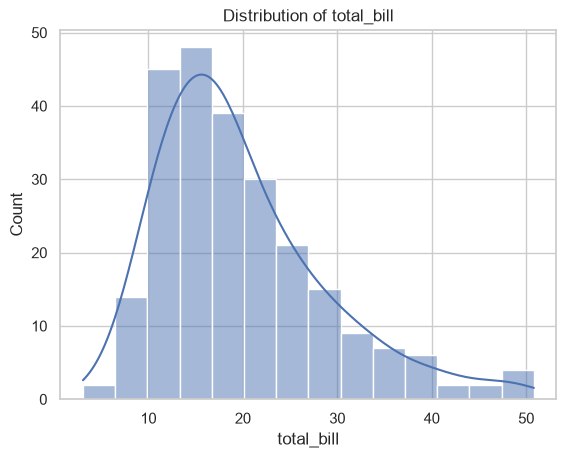

In [119]:
# Distribution of a numeric variable
sns.histplot(data=tips, x="total_bill", kde=True)
plt.title("Distribution of total_bill")
plt.show()

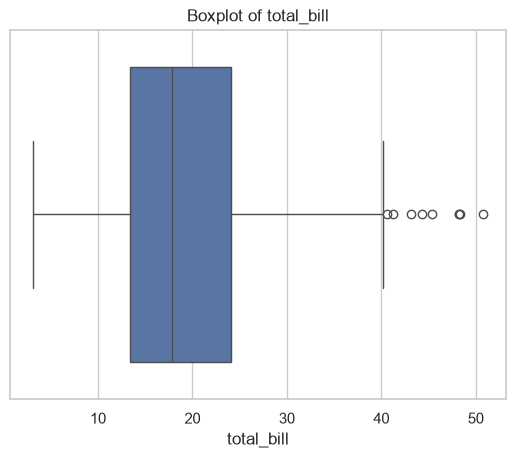

In [120]:
# Boxplot reveals spread and outliers
sns.boxplot(data=tips, x="total_bill")
plt.title("Boxplot of total_bill")
plt.show()

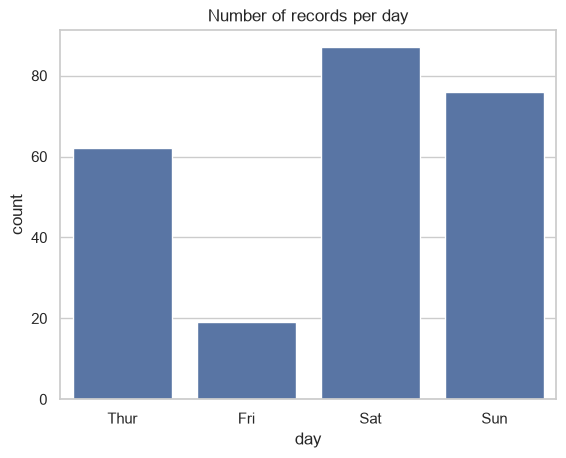

In [121]:
# Counts of a categorical variable
sns.countplot(data=tips, x="day")
plt.title("Number of records per day")
plt.show()

## 4.2 Bivariate Analysis

Explore relationships between two variables.

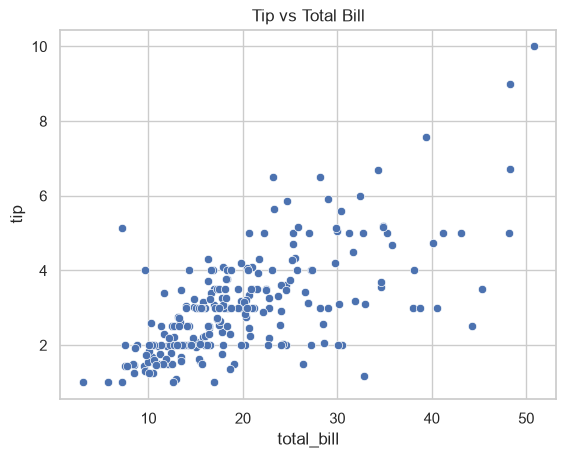

In [122]:
# Numeric vs numeric -> scatter
sns.scatterplot(data=tips, x="total_bill", y="tip")
plt.title("Tip vs Total Bill")
plt.show()

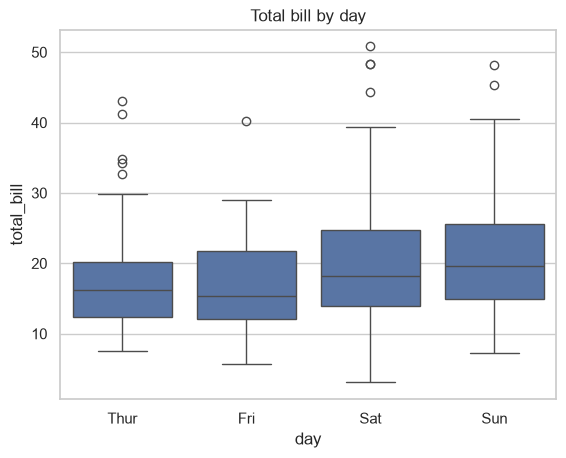

In [123]:
# Numeric vs categorical -> boxplot per category
sns.boxplot(data=tips, x="day", y="total_bill")
plt.title("Total bill by day")
plt.show()

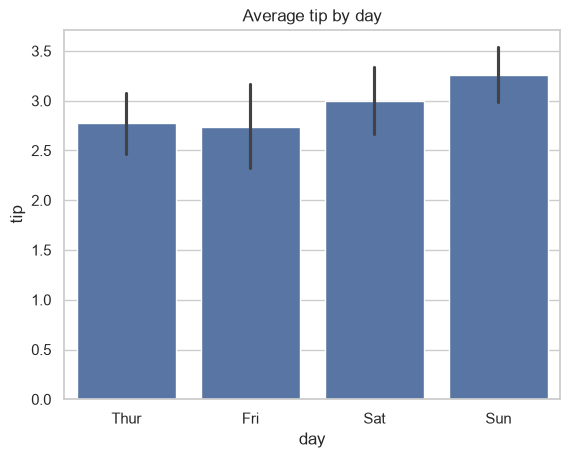

In [124]:
# Categorical summary -> barplot (shows mean + CI by default)
sns.barplot(data=tips, x="day", y="tip")
plt.title("Average tip by day")
plt.show()

## 4.3 Multivariate Analysis

Bring several variables together. `hue` adds a third dimension by colour.

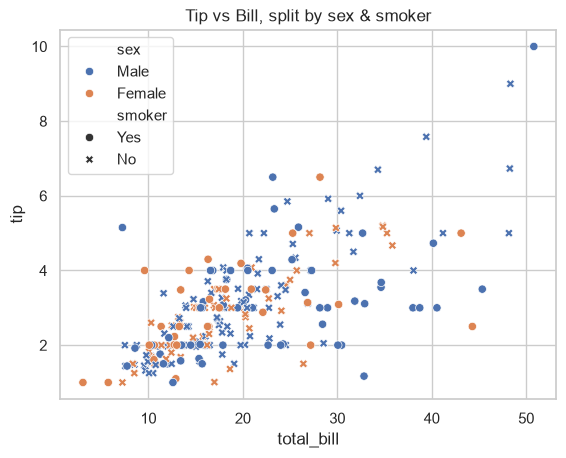

In [125]:
# Add a categorical dimension with hue
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="sex", style="smoker")
plt.title("Tip vs Bill, split by sex & smoker")
plt.show()

### Correlation matrix + heatmap
Correlation measures how strongly two numeric variables move together (−1 to +1).

            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000


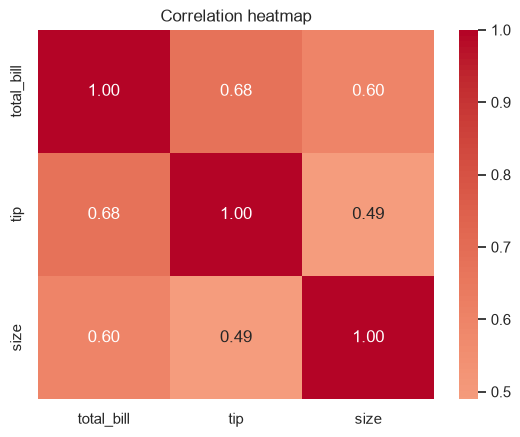

In [126]:
# Correlation only makes sense on numeric columns
corr = tips.select_dtypes("number").corr()
print(corr)

sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

### `pairplot` — every numeric pair at once
Great for a quick multivariate overview (can be slow on big data).

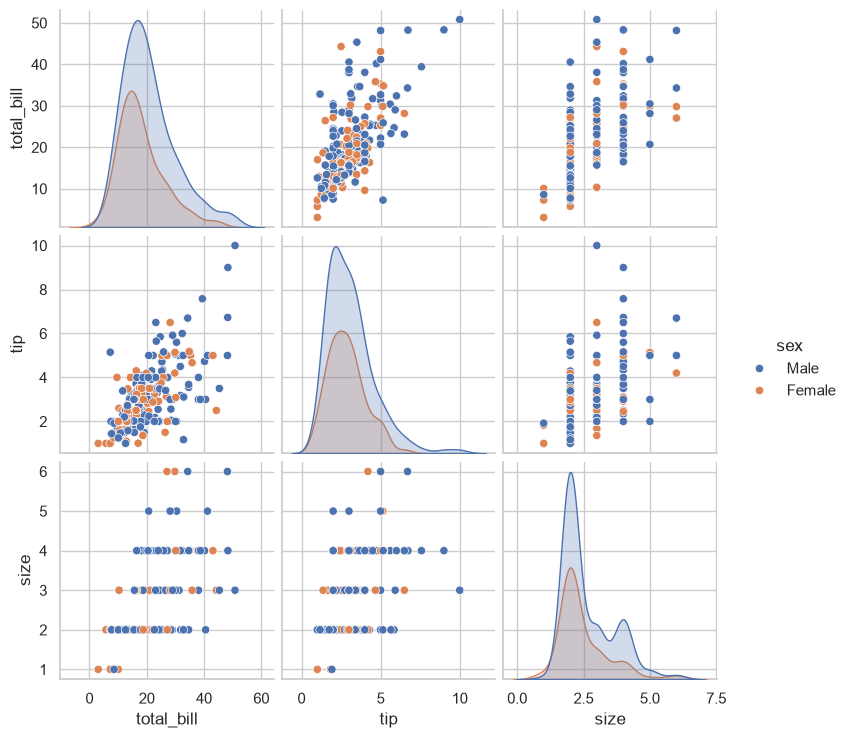

In [127]:
sns.pairplot(tips, hue="sex")
plt.show()

---
## 🧪 Lecture 4 Tasks — Seaborn & EDA (Wine Quality dataset)

Use the same **`winequality-red.csv`** file (semicolon-separated). Run the loader, then
work through a mini EDA: univariate → bivariate → multivariate.

**Quick drills:** Tasks 1–3   •   **Challenges:** Tasks 4–5


In [128]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

wine = pd.read_csv("winequality-red.csv", sep=",")
print("shape:", wine.shape)
wine.head()

shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


**Task 1 (drill · univariate).** Plot the distribution of the `alcohol` column using a histogram with a KDE curve. Is it roughly symmetric or skewed?

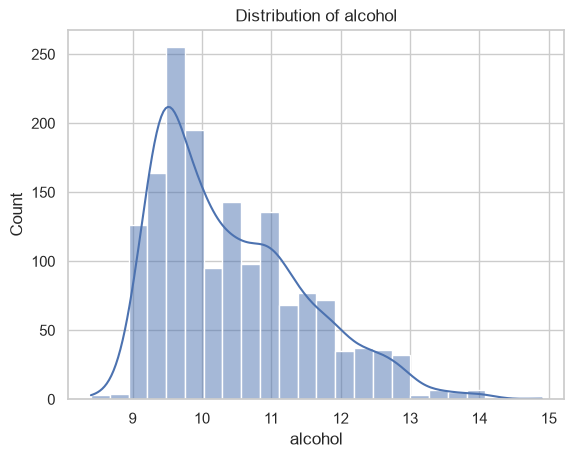

In [129]:
sns.histplot(data=wine, x="alcohol", kde=True)

plt.title("Distribution of alcohol")
plt.show()

**Task 2 (drill · univariate).** Use a `countplot` to show how many wines fall at each `quality` score. Which score is most common?

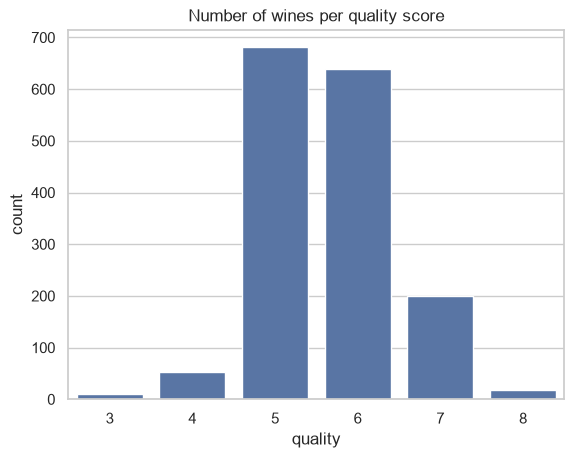

In [130]:
sns.countplot(data=wine, x="quality")
plt.title("Number of wines per quality score")
plt.show()

**Task 3 (drill · bivariate).** Draw a boxplot of `alcohol` grouped by `quality`. Does higher quality tend to have higher alcohol?

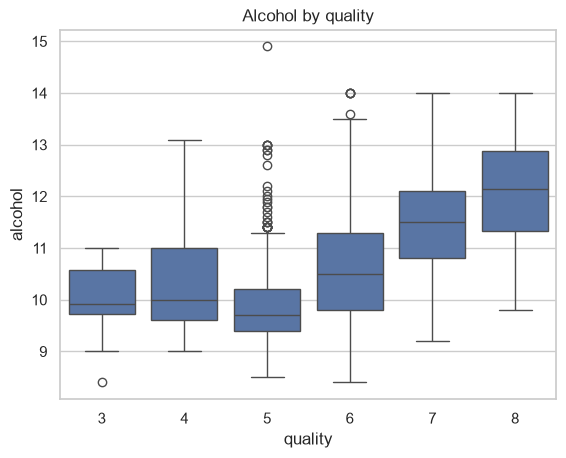

In [131]:
sns.boxplot(data=wine, x="quality", y="alcohol")
plt.title("Alcohol by quality")
plt.show()

**Task 4 (challenge · multivariate).** Build a **correlation heatmap** of all numeric columns.
1. Compute the correlation matrix.
2. Plot it with `annot=True` and a diverging colormap.
3. Which **two** features are most strongly correlated with `quality`?

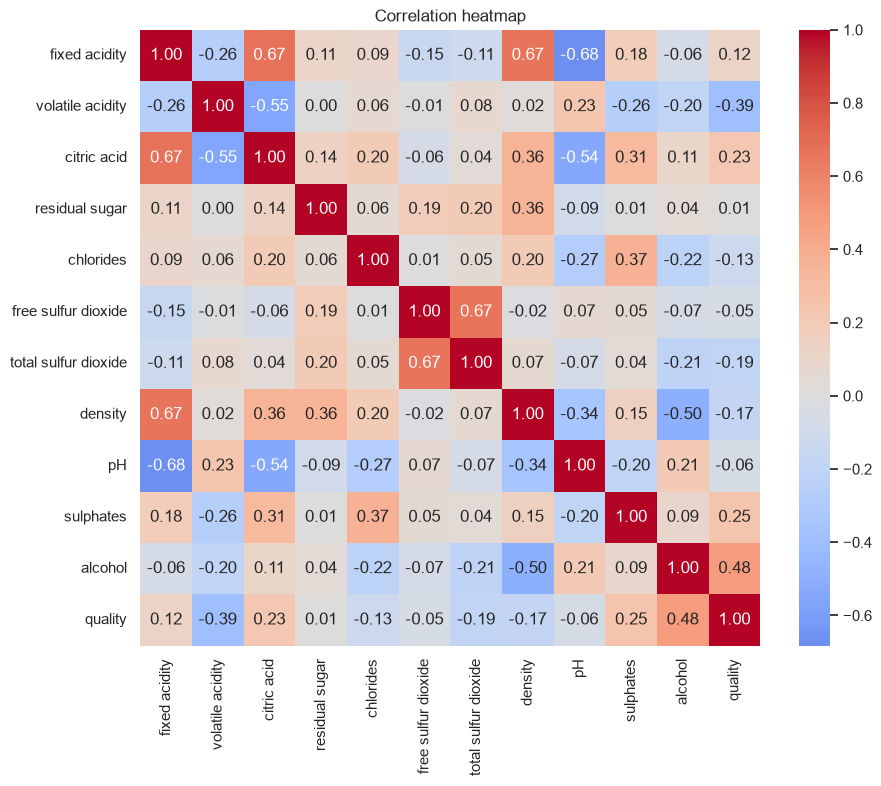

Features most correlated with quality:
alcohol             0.476166
volatile acidity    0.390558
Name: quality, dtype: float64


In [132]:
corr = wine.select_dtypes("number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

quality_corr = corr["quality"].drop("quality").abs().sort_values(ascending=False)
print("Features most correlated with quality:")
print(quality_corr.head(2))

**Task 5 (challenge · full mini-EDA).** Investigate what separates good wines from bad ones.
1. Create `quality_label` = 'high' if `quality >= 7` else 'low'.
2. Draw a scatterplot of `alcohol` vs `volatile acidity`, coloured by `quality_label` (`hue`).
3. Use `groupby` to print the mean of `alcohol`, `volatile acidity`, and `sulphates` for each label.
4. Write 1–2 sentences summarising what makes a high-quality wine.

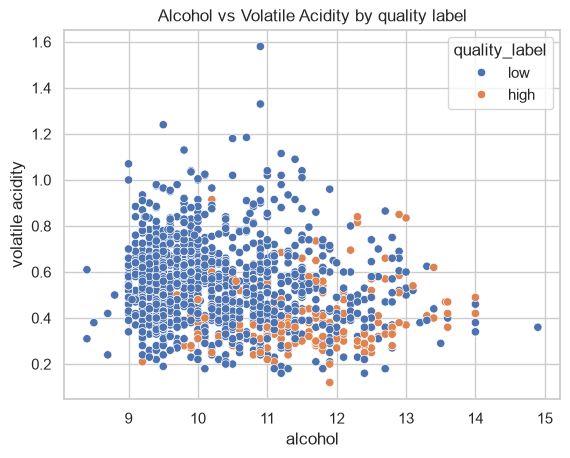

                 alcohol  volatile acidity  sulphates
quality_label                                        
high           11.518049          0.405530   0.743456
low            10.251037          0.547022   0.644754


In [133]:
wine["quality_label"] = np.where(wine["quality"] >= 7, "high", "low")

sns.scatterplot(data=wine, x="alcohol", y="volatile acidity", hue="quality_label")
plt.title("Alcohol vs Volatile Acidity by quality label")
plt.show()

print(wine.groupby("quality_label")[["alcohol", "volatile acidity", "sulphates"]].mean())